In [23]:
import os
import pandas as pd
import numpy as np
import pickle
import json 

import seaborn as sns
import matplotlib.pyplot as plt
from nilearn import plotting
import matplotlib.cm as cm
import matplotlib.ticker as mticker
import matplotlib as mpl
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from sklearn.metrics import f1_score
from scipy.stats import spearmanr, linregress
from statsmodels.stats.multitest import multipletests

from src.config import OUT_PATH, COL_REG, DATA_PATH, col_pc, PROJECT_PATH, color_event
from src.setting import ExcludSubj, GetInfo
from src.decomposition import CompoThr, prep_data_trial
from src.decoding import cleandfdecodingTS
from src.behavior import extract_RT, adjust_pvalues, significance, get_cross_point, get_slop_pc2, area_pc2, get_slop_pc3

In [30]:
band = 'high_gamma'
method_pca = 'concat'
PCS = [0, 1, 2]

dataset_label = 'mf70-160'
path_behavior=PROJECT_PATH + '/misc/events'
tfr_path = DATA_PATH + '/Data_longWOBS_' + dataset_label
subj_included = [file.replace('_TFRtrials.p', '') for file in os.listdir(tfr_path) if file[-len('TFRtrials.p'):] == 'TFRtrials.p']
subj_included = ExcludSubj(subj_included, data_path=tfr_path)
interesting_ev = [0, 1]

subj_included_restricted = {16: ['BJH072', 'LL36', 'BJH069', 'SLCH020', 'BJH045', 'LL14', 'BJH050',
       'BJH027', 'OS70', 'BJH052', 'OS61', 'BJH041', 'BJH046', 'BJH056',
       'LL31', 'BJH039', 'BJH042', 'BJH026', 'LL08', 'SLCH018', 'BJH029',
       'DA037', 'BJH058', 'SLCH024', 'BJH049']}

print('Subject number : ', len(subj_included))
coord, areas, elect_list, subj_list, regions_list = GetInfo(subj_included, data_path=tfr_path)

compo = pd.read_csv(OUT_PATH + f'/grpPCA_mf70-160/supsubj_{method_pca}/grp_{method_pca}_Compo_PCA5.csv').drop(columns = 'Unnamed: 0').query('freq == @band')
ts = pd.read_csv(OUT_PATH + f'/grpPCA_mf70-160/supsubj_{method_pca}/grp_{method_pca}_Xtrans_PCA5.csv').drop(columns = ['Unnamed: 0']).query('freq == @band')

print('Explained Variances: ', ts.expl_var.values)

info_file = tfr_path + f'/{subj_included[0]}_info.json'
with open(info_file) as f:
    info = json.load(f)
    time= info['time_tfr']

for col in ['expl_var', 'compo', 'freq', 'subj'] : 
    if col in compo.columns : 
        compo = compo.drop(columns = col)

    if col in ts.columns : 
        ts = ts.drop(columns = col)
        
ts = ts.values
compo = compo.values

Subject number :  30
Explain Variance:  [0.28444243 0.08678816 0.03928761 0.02900684 0.02134747]


# Network Dynamics

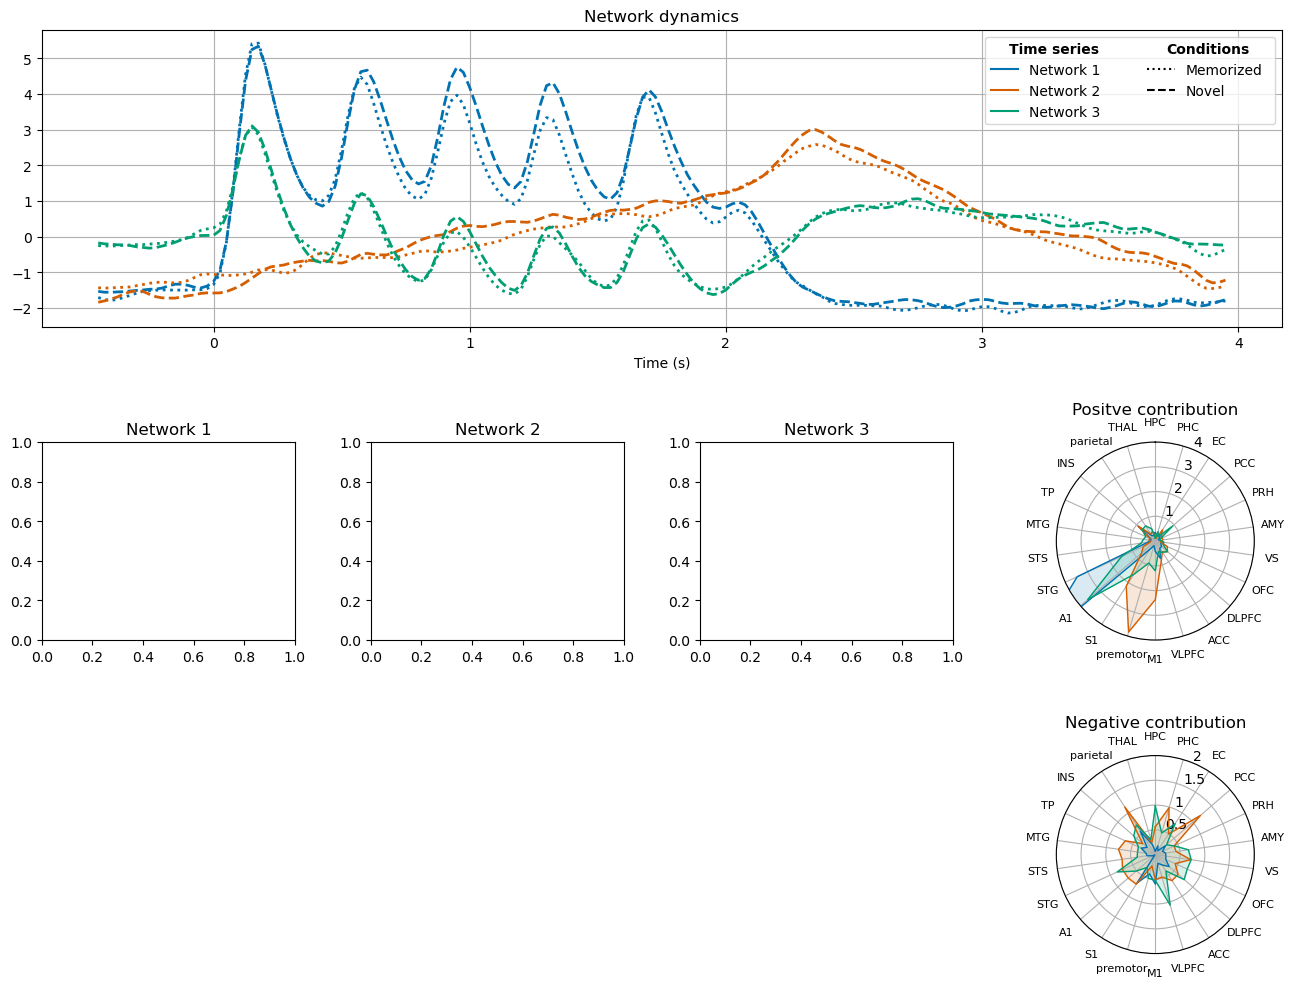

In [42]:
# data grp 
ts_pc=np.concat([ts[None, PCS, :int(ts.shape[1]/2)], ts[None, PCS, int(ts.shape[1]/2):]], axis = 0)

# plot topo pc1, ts, pc2 for each tp
fig = plt.figure(figsize=(16, 12))
gs = gridspec.GridSpec(3, 4, height_ratios=[3/5, 2/5, 2/5], hspace=0.5, wspace=0.3)
ax_TS = fig.add_subplot(gs[0, :])  

ax_w0 = fig.add_subplot(gs[1, 0])
ax_w1 = fig.add_subplot(gs[1, 1])
ax_w2 = fig.add_subplot(gs[1, 2])

for i, a in enumerate([ax_w0, ax_w1, ax_w2]) :
    a.set_title('Network ' + str(i +1))

ax_w3 = fig.add_subplot(gs[1, 3], polar=True)
ax_w4 = fig.add_subplot(gs[2, 3], polar=True)

for pc_use in PCS : 
    ax_TS.plot(time[20:], ts_pc[0, pc_use, 20:].T, c=col_pc[pc_use], ls=':', linewidth = 2)
    ax_TS.plot(time[20:], ts_pc[1, pc_use, 20:].T, c=col_pc[pc_use], ls='--', linewidth = 2)

ax_TS.grid()
ax_TS.set_xlabel('Time (s)')
ax_TS.set_title('Network dynamics')

data_thr = compo
df_data = pd.DataFrame(data_thr.T)
df_data['region'] = regions_list

# missing regions 
df_data[[0, 1, 2, 3]] = df_data[[0, 1, 2, 3]].astype(float)
df_data = df_data[df_data['region'] != 'N']
df_abs = df_data.copy().drop(columns = ['region']).apply(lambda x : abs(x))
df_abs['region'] = df_data['region']
df_abs.loc[:, 'region'] = df_abs.loc[:, 'region'].fillna('NON')

# PLOT 
regions = np.unique(df_data['region'])
n_regions = len(regions)

angles = np.linspace(0, 2 * np.pi, n_regions, endpoint=False)
angles = np.concatenate([angles, [angles[0]]])


# pos and neg sum /count 
for PC_use in PCS : 
    pos_sum = df_data[df_data[PC_use] > 0][[PC_use, 'region']].groupby('region').sum().reindex(COL_REG.keys()).fillna(0).drop(index='N').values
    neg_sum = df_data[df_data[PC_use] < 0][[PC_use, 'region']].groupby('region').sum().reindex(COL_REG.keys()).fillna(0).drop(index='N').values
    count = df_data[[PC_use, 'region']].groupby('region').count().reindex(COL_REG.keys()).fillna(0).drop(index='N').values

    pos_sum = np.concatenate([pos_sum, [pos_sum[0]]])[:, 0]
    neg_sum = np.concatenate([neg_sum, [neg_sum[0]]])[:, 0]
    count = np.concatenate([count, [count[0]]])[:, 0]

    ax_w3.plot(angles, pos_sum/count, linewidth=1, label=f"PC{PC_use}", c = col_pc[PC_use])
    ax_w3.fill(angles, pos_sum/count, alpha=0.15, c = col_pc[PC_use])
    ax_w3.set_title('Positve contribution', y=1.1)

    ax_w4.plot(angles, -neg_sum/count, linewidth=1, label=f"PC{PC_use}", c = col_pc[PC_use],)
    ax_w4.fill(angles, -neg_sum/count, alpha=0.15, c = col_pc[PC_use])
    ax_w4.set_title('Negative contribution', y=1.1)
    
    ax_w3.set_ylim(0, 0.04)
    ax_w4.set_ylim(0, 0.02)

    scale = 100  # change to 1e6 if you want micro-units etc.
    formatter = mticker.FuncFormatter(lambda x, pos: f"{x*scale:g}")
    ax_w3.yaxis.set_major_formatter(formatter)
    ax_w4.yaxis.set_major_formatter(formatter)

for a in [ax_w3, ax_w4] : 
    a.set_xticks(angles[:-1])
    a.set_xticklabels(list(COL_REG.keys())[:-1], fontsize=8)
    a.set_theta_offset(np.pi / 2)
    a.set_theta_direction(-1)

legend_lines = []
legend_lines = [Line2D([], [],linestyle='None', label='Time series'), 
                    Line2D([0], [0], color=col_pc[0], label='Network 1'),
                    Line2D([0], [0], color=col_pc[1], label='Network 2'),
                    Line2D([0], [0], color=col_pc[2], label='Network 3'),
                    Line2D([], [],linestyle='None', label='Conditions'), 
                    Line2D([0], [0], linestyle=':', color='black', label='Memorized'),
                    Line2D([0], [0], linestyle='--', color='black', label='Novel')]

leg = ax_TS.legend(handles= legend_lines, ncol=2)

for h, txt in zip(leg.legend_handles, leg.get_texts()):
    if txt.get_text() in ['Conditions',  'Time series']:
        h.set_visible(False)
        txt.set_weight('bold')
        txt.set_x(-20)


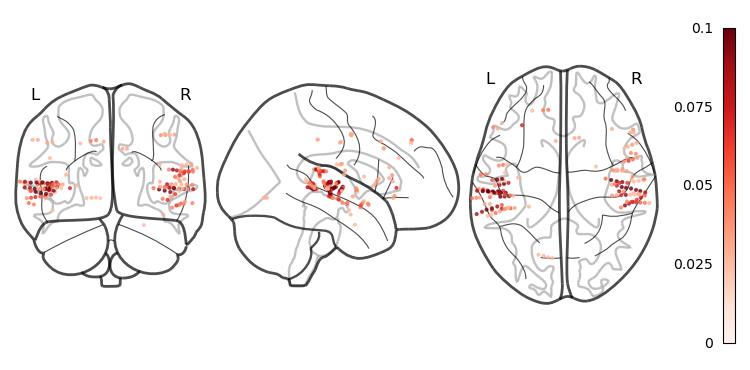

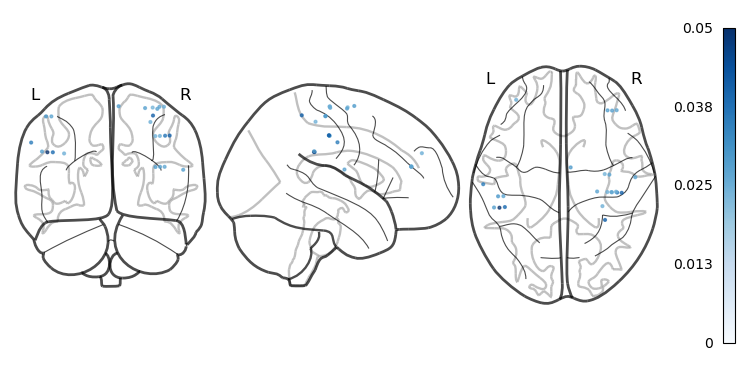

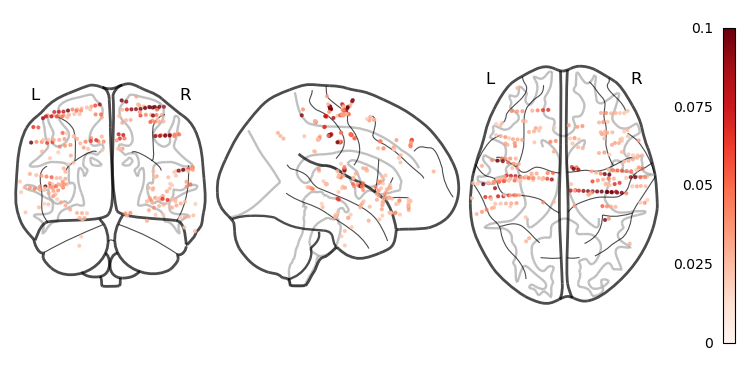

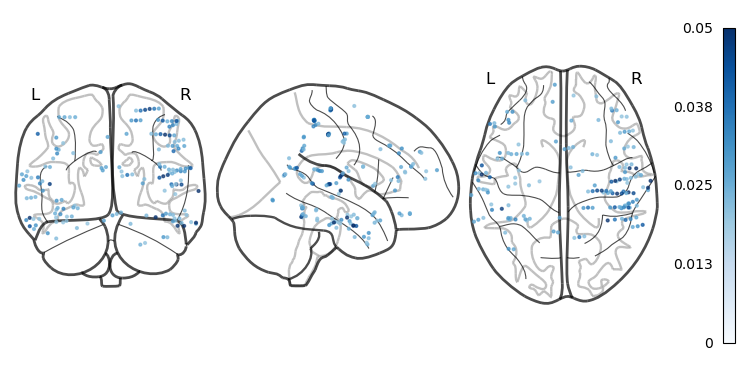

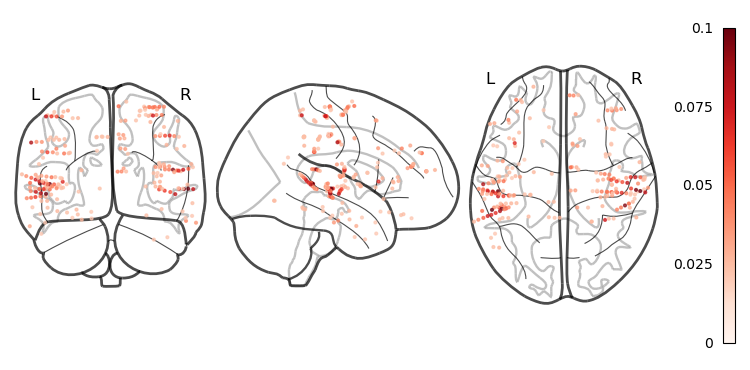

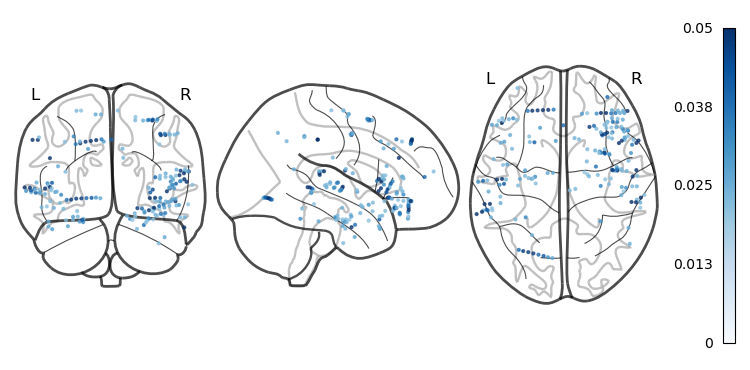

In [43]:
data_thr = CompoThr(compo, replace=np.nan)
df_data = pd.DataFrame(data_thr.T)

for PC_use in PCS : 
    
    pos = df_data.copy().clip(lower=0).values[:, PC_use]

    mask = (~np.isnan(pos)) & (pos > 0)
    values_filt = pos[mask]
    coords_filt = np.array(coord)[mask]

    fig = plotting.plot_markers(node_coords = np.array(coords_filt),  
                                      node_size=4, 
                                      node_values=values_filt,
                                      node_cmap='Reds',
                                      display_mode='ortho',
                                      node_vmin=0, 
                                      node_vmax=0.1) 
    neg = df_data.copy().clip(upper=0).values[:, PC_use]
    mask = (~np.isnan(neg)) & (neg < 0)
    values_filt = neg[mask]
    coords_filt = np.array(coord)[mask]

    fig = plotting.plot_markers(node_coords = np.array(coords_filt),  
                                      node_size=4, 
                                      node_values=-values_filt,
                                      node_cmap='Blues',
                                      display_mode='ortho', 
                                      node_vmin=0, 
                                      node_vmax=0.05) 

### Suplement: Comparison with the mean PCA

Text(50.722222222222214, 0.5, 'Mean')

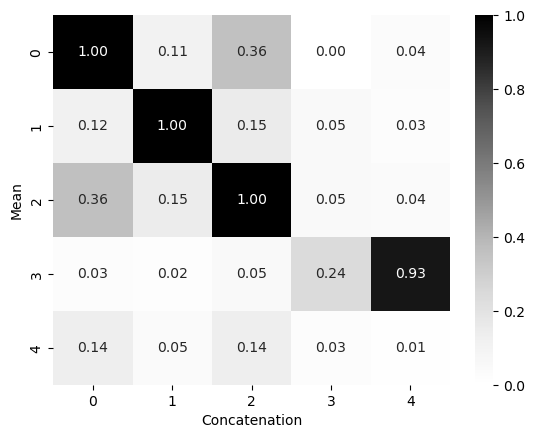

In [52]:
method = 'pca'
df_mean_compo=pd.read_csv(f'{OUT_PATH}/grp{method.upper()}_{dataset_label}/supsubj_mean/grp_mean_Compo_{method.upper()}5.csv').drop(columns = ['Unnamed: 0', 'compo'])
df_concat_compo=pd.read_csv(f'{OUT_PATH}/grp{method.upper()}_{dataset_label}/supsubj_concat/grp_concat_Compo_{method.upper()}5.csv').drop(columns = ['Unnamed: 0', 'compo'])

mean_compo = df_mean_compo.query('freq == @band').drop(columns = 'freq').values
concat_compo = df_concat_compo.query('freq == @band').drop(columns = 'freq').values

R = np.zeros((mean_compo.shape[0], concat_compo.shape[0]))
P = np.zeros((mean_compo.shape[0], concat_compo.shape[0]))

for i in range(mean_compo.shape[0]):
    for j in range(concat_compo.shape[0]):
        r, pval = spearmanr(mean_compo[i, :], concat_compo[j, :])
        R[i, j] = r
        P[i, j] = pval

sns.heatmap(abs(R), vmin=0, vmax=1, cmap='Greys', annot=True , fmt='.2f')
plt.xlabel('Concatenation')
plt.ylabel('Mean')

### Suplement: Subject PCA correlation

In [44]:
grp_PCA = pd.read_csv(f'{OUT_PATH}/grpPCA_{dataset_label}/supsubj_concat/grp_concat_Xtrans_PCA5.csv', index_col=0)
grp_PCA = grp_PCA.query('subj == "grp" and freq == "high_gamma"').drop(columns = ['freq', 'subj', 'compo', 'expl_var']).values
subj_PCA = pd.read_csv(f'{OUT_PATH}/subjPCA_{dataset_label}/TFR/subj_Xtrans_PCA5_concat.csv', index_col=0)
subj_PCA = subj_PCA.query('freq == "high_gamma"').drop(columns = ['freq', 'compo', 'expl_var'])

In [45]:
rho = {}
for subj in subj_included : 
    subj_data = subj_PCA.query('subj == @subj').drop(columns = ['subj']).values
    # Spearman correlation 
    r = np.zeros((3, 3))
    p=np.zeros((3, 3))
    for c1 in range(3) :
        for c2 in range(3):
            r[c1, c2], p[c1, c2] = spearmanr(subj_data[c1, :], grp_PCA[c2, :])
    rho[subj] = r


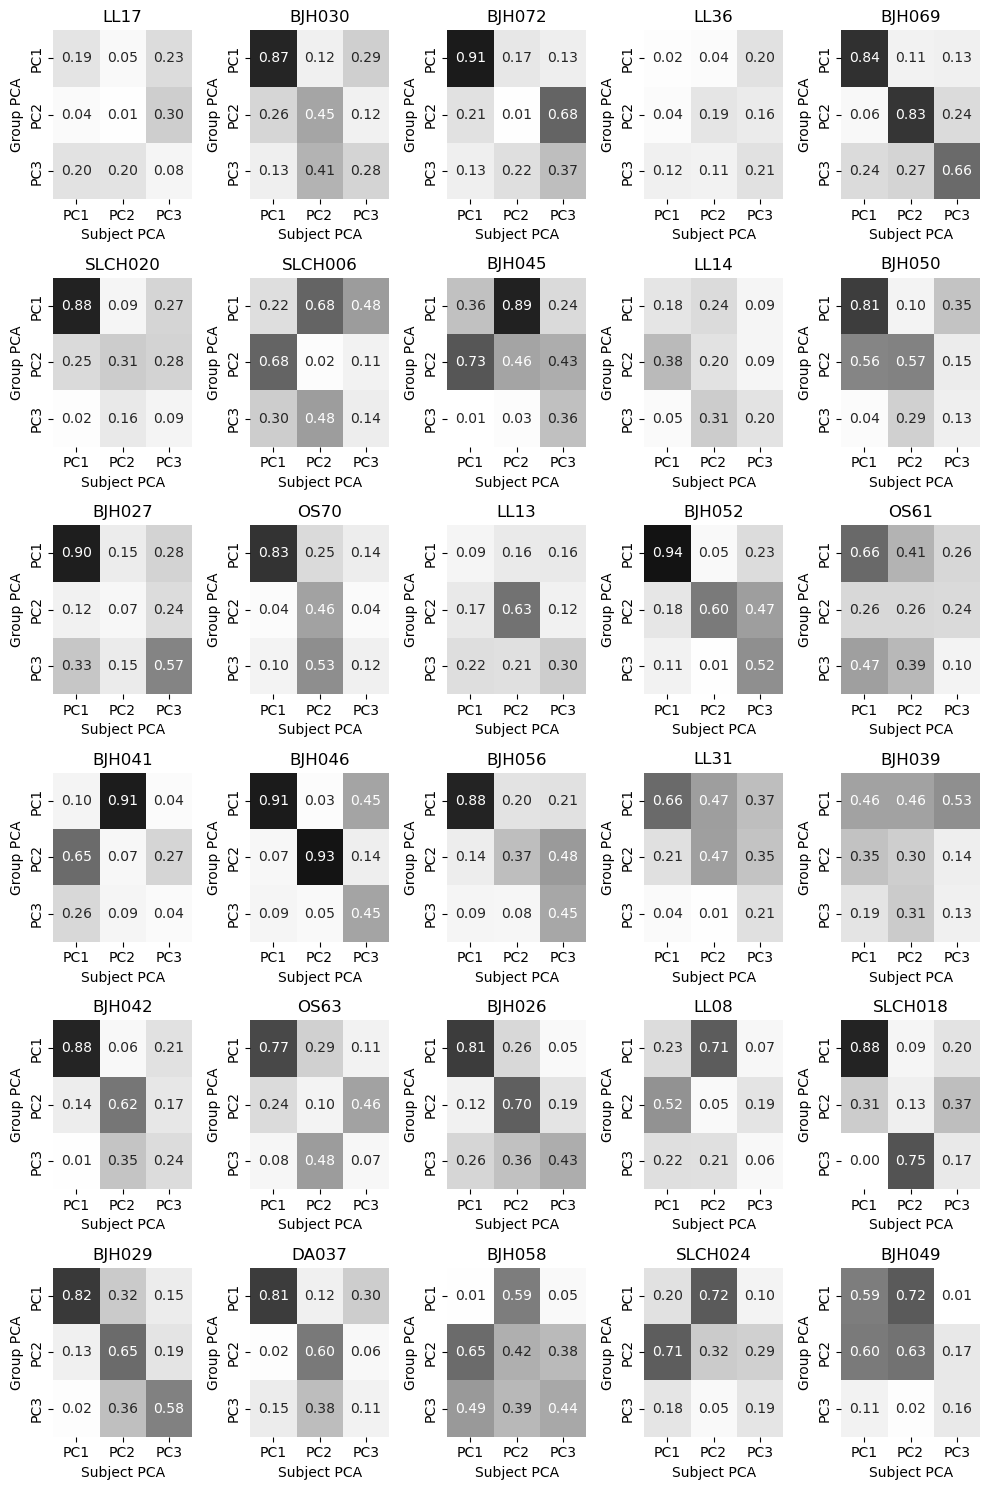

In [46]:
fig, ax = plt.subplots(6, 5, figsize = (10, 15))

for subj, a in zip(subj_included, ax.flatten()) : 
    sns.heatmap(abs(rho[subj]), annot=True, fmt=".2f", cbar=False, ax=a, vmin=0, vmax=1, cmap='Greys')
    a.set_title(subj)
    a.set_ylabel('Group PCA')
    a.set_xlabel('Subject PCA')
    a.set_xticklabels(['PC1', 'PC2', 'PC3'])
    a.set_yticklabels(['PC1', 'PC2', 'PC3'])
fig.tight_layout()

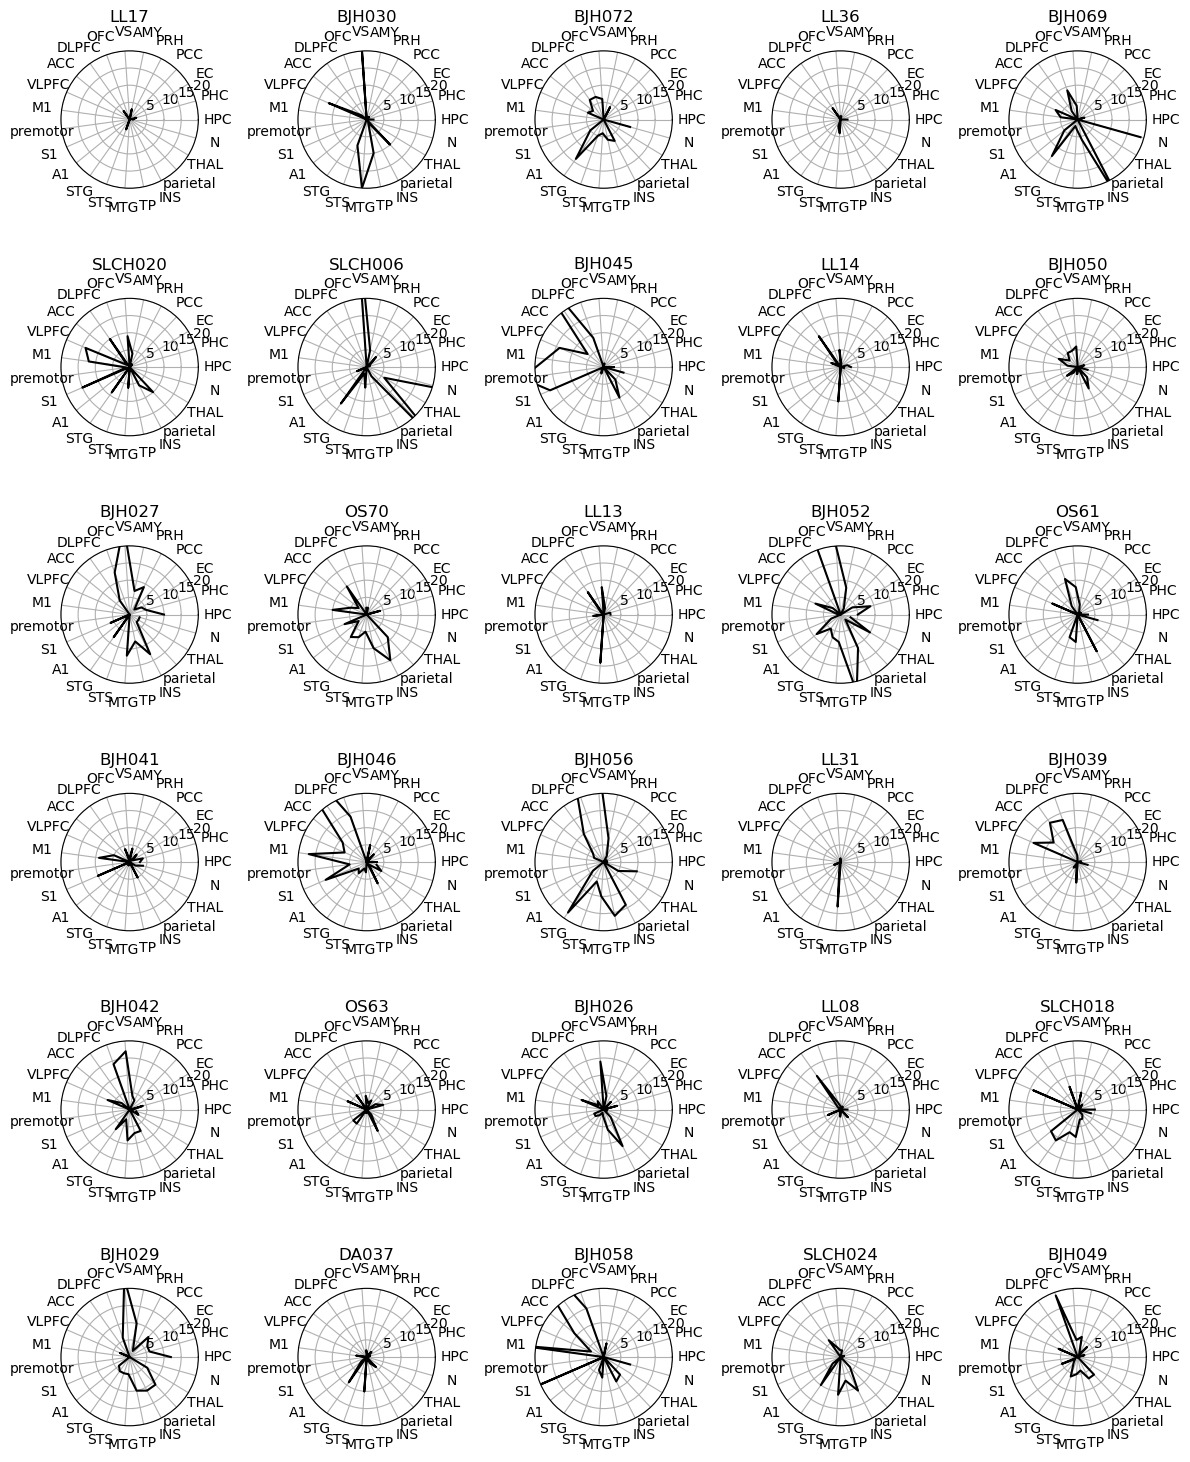

In [47]:
df_info = pd.DataFrame({'subj': subj_list,'area': areas,'region': regions_list})
region_order = COL_REG
theta = np.linspace(0, 2 * np.pi, len(region_order), endpoint=False)

fig, axs = plt.subplots(6, 5,figsize=(12, 15),subplot_kw={'projection': 'polar'},)

for subj, ax in zip(subj_included, axs.flatten()):
    ax.set_ylim(0, 20)
    df_sub = df_info.query('subj == @subj')

    counts = (df_sub.groupby('region').size().reindex(region_order, fill_value=0))
    
    ax.plot(theta, counts.values, c='k')
    ax.set_xticks(theta)
    ax.set_xticklabels(region_order)
    ax.set_title(str(subj), y=1.15)

fig.tight_layout()


[Text(0, 0.5, 'PC1'), Text(0, 1.5, 'PC2'), Text(0, 2.5, 'PC3')]

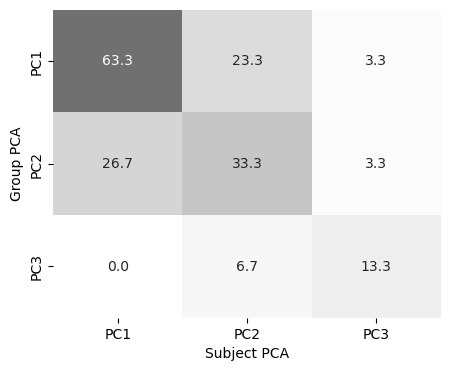

In [48]:
# count how many times we have the correlation above 0.5 for each of the componants
fig, ax = plt.subplots(figsize=(5, 4))
count = np.zeros((3, 3))
for subj in subj_included :
    count += (abs(rho[subj]) > 0.5).astype(int)
sns.heatmap(count/30  *100, annot=True, fmt=".1f", cbar=False, vmin=0, vmax=100, cmap='Greys')
ax.set_ylabel('Group PCA')
ax.set_xlabel('Subject PCA')
ax.set_xticklabels(['PC1', 'PC2', 'PC3'])
ax.set_yticklabels(['PC1', 'PC2', 'PC3'])

# Decoding

In [56]:
data_aug_method = 'mean'
PC_use = 2
model_name = 'RandomForest'
time = time

df_final = pd.read_csv(OUT_PATH + f'/Decoding_shuffled_trials_{dataset_label}_perm10000/{band}/fullmodel/{method_pca}_{data_aug_method}_{PC_use}_{model_name}full.csv')
result = cleandfdecodingTS(df_final, len(time))

print('Class Balance :', np.unique(result['y_pred'], return_counts=True)[1][0]/2, np.unique(result['y_pred'], return_counts=True)[1][1]/2)
print('General Accuracy:', result['acc'])
print('F1 score:', f1_score(result['y_pred'], result['y_test']))
print('General Accuracy Permuted:', result['acc_sh'])
print('Hyperparam: ', df_final.best_param[0])

Class Balance : 57.0 43.0
General Accuracy: 0.56
F1 score: 0.5268817204301075
General Accuracy Permuted: 0.498245
Hyperparam:  {'max_depth': 5, 'max_features': 'log2', 'n_estimators': 50}


In [60]:
y_pred = result['y_pred'].reshape(100, 2)
y_test = result['y_test'].reshape(100, 2)
y_pred_sh = result['y_pred_sh'].reshape(100,2, 1000)

acc_obs = np.mean(y_pred == y_test, axis=1)
acc_null = np.mean(y_pred_sh == y_test[:, :, None],axis=1)

Tobs = np.mean(acc_obs)
Tnull = np.mean(acc_null, axis=0)

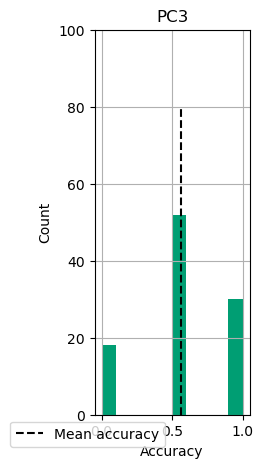

In [61]:
fig, ax = plt.subplots(figsize=(2, 5))
ax.hist(acc_obs, color=col_pc[PC_use])
ax.grid()
ax.set_xlabel('Accuracy')
ax.set_ylabel('Count')
ax.vlines(x=np.mean(acc_obs), ymin=0, ymax=80, ls='--', color='k', label='Mean accuracy')
ax.set_ylim(0, 100)
ax.set_title(f'PC{PC_use+1}')
ax.legend(bbox_to_anchor=(0.5, 0))

In [62]:
p_value = (1 + np.sum(Tnull >= Tobs)) / (len(Tnull) + 1)

print("Tobs:", Tobs)
print("Mean Tnull:", np.mean(Tnull))
print("p-value:", p_value)

Tobs: 0.56
Mean Tnull: 0.498245
p-value: 0.05194805194805195


(-0.5, 4.0)

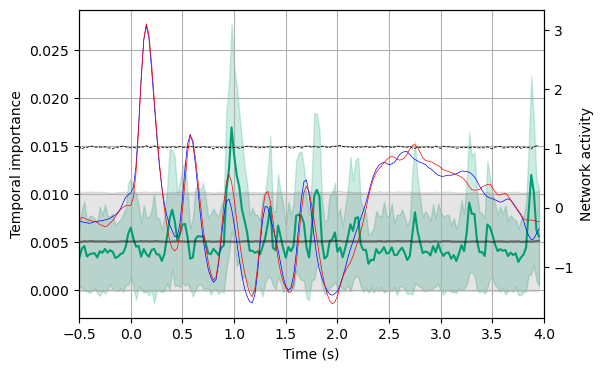

In [63]:
# IF WEIGHTS
weight_mean= result['weight_mean']
weight_std= result['weight_std']
weight_sh_mean= result['weight_sh_mean']
weight_sh_std= result['weight_sh_std']

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(time, weight_mean, color=col_pc[PC_use], label = 'Mean model coefficients over 100 iter')
ax.fill_between(time, weight_mean - weight_std,weight_mean+weight_std, alpha = 0.2, color = col_pc[PC_use], label = 'Sd model coefficients over 100 iter')
ax.plot(time, weight_sh_mean, color='black',alpha=0.5,  label = f'Mean {int(df_final.loc[0, "iter_perm"])}-perm model over {int(df_final.loc[0, "iter"])} iter')
ax.fill_between(time, abs(weight_sh_mean)- weight_sh_std, abs(weight_sh_mean) + weight_sh_std, alpha = 0.1, color = 'black', label = f'Sd {int(df_final.loc[0, "iter_perm"])}-perm model')
#ax.plot(time[20:], - np.percentile(result['weight_sh'], 95, axis=0)[20:], alpha = 1,ls='--', linewidth=0.6, color = 'black')
ax.plot(time, np.percentile(result['weight_sh'], 95, axis=0), alpha = 1, ls='--', linewidth=0.6, color = 'black', label = f'95% percentil {int(df_final.loc[0, "iter_perm"])}-perm model')


transform = pd.read_csv(OUT_PATH +  f'/grpPCA_{dataset_label}/supsubj_{method_pca}/grp_{method_pca}_Xtrans_PCA5.csv')
compo_lab = 'compo' + str(PC_use+1)
time_serie_df = transform.query('freq == @band and compo == @compo_lab')

for col in ['Unnamed: 0', 'freq' , 'compo', 'subj', 'expl_var'] :
    if col in time_serie_df.columns :
        time_serie_df = time_serie_df.drop(columns = col)
time_serie = time_serie_df.values

axt = ax.twinx()
axt.plot(time,  time_serie[0 ,:int(time_serie.shape[1]/2)], label = 'Old/Correct - Grp level', c = 'b', alpha = 1, linewidth=0.5)
axt.plot(time, time_serie[0, int(time_serie.shape[1]/2):], label = 'New/Correct - Grp level', c = 'r', alpha = 1, linewidth=0.5)
axt.set_ylabel('Network activity')
ax.legend(bbox_to_anchor = (0.5, -0.25),loc ='center', ncol  =2)
ax.set_xlabel('Time (s)')
ax.set_ylabel('Temporal importance')
ax.grid()
ax.legend_.remove()
ax.set_xlim(-0.5, 4)


# Behavioral Analysis

In [3]:
df_RT = extract_RT(subj_included=subj_included, path_behavior=path_behavior, path_info=tfr_path)

/tmp/ipykernel_11121/2650579812.py:26: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax[1].boxplot(data,labels=conditions,patch_artist=True,showfliers=True)


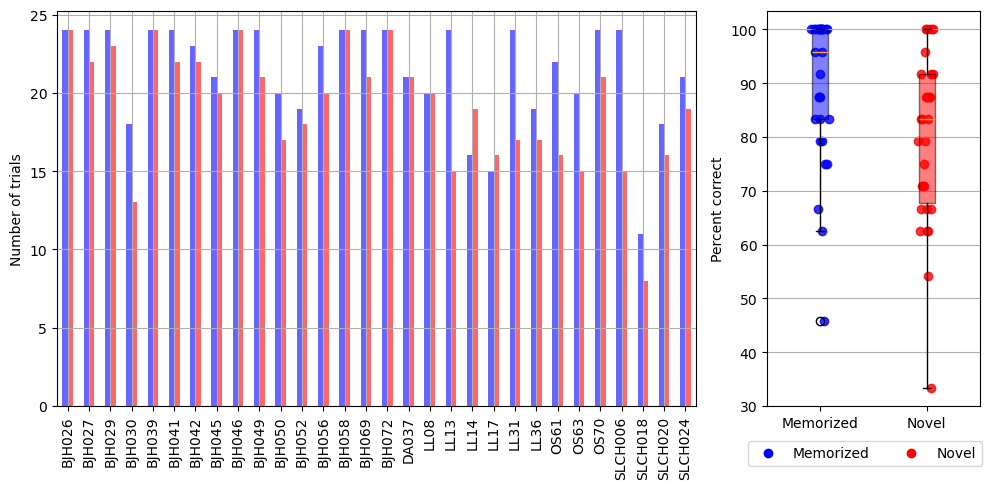

In [4]:
df = df_RT.copy()
df["ev_id"] = df["ev_id"].astype(str)
df["cond"] = df["ev_id"]
df.loc[df["cond"] == "1", "cond"] = "Memorized"
df.loc[df["cond"] == "2", "cond"] = "Novel"
df.loc[df["cond"].isin(['101','102','201','202']), "cond"] = "Failed"
trial_counts = (df.groupby(["subject", "cond"]).size().reset_index(name="n_trials"))
trial_counts = trial_counts[trial_counts['cond'].isin(["Memorized", "Novel"])]
pivot_counts = trial_counts.pivot(index="subject",columns="cond",values="n_trials").fillna(0)

fig, ax=plt.subplots(1, 2, width_ratios=[3/4, 1/4], figsize=(10, 5)) #, sharey=True)
colors = {'Memorized': 'b', 'Novel': 'r', 'Failed': 'k'}
pivot_counts.plot(kind="bar", color=colors,alpha = 0.6, ax=ax[0])
# Custom legencna d
legend_handles = [Patch(facecolor='b', alpha=0.6, label='Memorized'),Patch(facecolor='r', alpha=0.6, label='Novel'),Patch(facecolor='k', alpha=0.6, label='Failed')]

ax[0].legend(handles=legend_handles, title="Trial type")
ax[0].set_ylabel("Number of trials")
ax[0].set_xlabel("")
ax[0].grid()

conditions = ['Memorized', 'Novel'] #, 'Failed']

data = [trial_counts.loc[trial_counts['cond'] == c, 'n_trials']/24*100 for c in conditions]

bp = ax[1].boxplot(data,labels=conditions,patch_artist=True,showfliers=True)
for patch, cond in zip(bp['boxes'], conditions):
    patch.set_facecolor(colors[cond])
    patch.set_alpha(0.5)

for i, cond in enumerate(conditions, start=1):
    y = trial_counts.loc[trial_counts['cond'] == cond, 'n_trials']/24*100
    x = np.random.normal(i, 0.04, len(y))  # jitter
    ax[1].scatter(x, y, color=colors[cond], alpha=0.8)

ax[1].set_ylabel("Percent correct")
ax[1].grid(axis='y')


handles = [Line2D([0], [0], marker='o', linestyle='', color=color_event[0],label='Memorized', markersize=6),
                Line2D([0], [0], marker='o', linestyle='', color=color_event[1], label='Novel', markersize=6)]
                #Line2D([0], [0], marker='o', linestyle='', color='k', label='Failed', markersize=6)]

for a in ax:
    leg = a.get_legend()
    if leg is not None:
        leg.remove()

fig.legend(handles=handles,
           labels=['Memorized', 'Novel'], #, 'Failed'],
           loc='upper center',
           ncol=3,
           frameon=True,
           bbox_to_anchor=(0.87, 0.12))


plt.tight_layout()

In [5]:
df['success'] = df['ev_id'].map({'1':1, '2':1, '101':0, '102':0, '201':0, '202':0})
df['cond'] = df['ev_id'].map({'1':'Memorized', '2':'Novel', '101':'Memorized', '102':'Memorized', '201':'Novel', '202':'Novel'})
df.to_csv(OUT_PATH+ '/Behavior_mf70-160/behavG.csv')

from src.behavior import accuracy_above_chance_glmm, accuracy_by_condition_glmm, reaction_time_lmm
accuracy_above_chance_glmm(df)

{'accuracy': np.float64(0.925565923406696),
 'OR': np.float64(12.434706867713837),
 'OR_95CI_lower': np.float64(10.462708781365082),
 'OR_95CI_upper': np.float64(14.778384653251903),
 'z': np.float64(28.60975083030964),
 'p_one_sided': np.float64(0.0),
 'model': <statsmodels.genmod.bayes_mixed_glm.BayesMixedGLMResults at 0x7ff7d99aea70>}

In [6]:
accuracy_by_condition_glmm(df)

{'Novel_vs_Memorized_OR': np.float64(3.884615833959533),
 'OR_95CI_lower': np.float64(2.6699810836478455),
 'OR_95CI_upper': np.float64(5.651815389205744),
 'z': np.float64(7.093607210697081),
 'p': np.float64(1.3065104553788842e-12),
 'model': <statsmodels.genmod.bayes_mixed_glm.BayesMixedGLMResults at 0x7ff7d9a050c0>}

In [7]:
reaction_time_lmm(df)

{'condition_means': {'Memorized': 0.9887045208089262,
  'Novel': 0.9870769353076139},
 'fixed_effects': Intercept           0.985130
 C(cond)[T.Novel]    0.010011
 dtype: float64,
 '95CI':                          0         1
 Intercept         0.932643  1.037618
 C(cond)[T.Novel] -0.008221  0.028243
 Group Var         0.329139  1.090895,
 'p_values': Intercept           3.078019e-296
 C(cond)[T.Novel]     2.818372e-01
 Group Var            2.585046e-04
 dtype: float64,
 'model': <statsmodels.regression.mixed_linear_model.MixedLMResultsWrapper at 0x7ff7d98a7c70>}

In [8]:
nb_trials = 16
sorted_='RT'
rt_mean_all = np.zeros((2, nb_trials))

for ic, condi in enumerate(['1', '2'] ): 
    rt_subj = []
    for subj in subj_included_restricted[nb_trials]:
        df = df_RT[(df_RT['subject'] == subj)].reset_index(drop=True)
        df= df.dropna()
        if len(df) <4 : 
            print(subj)
        rt_condi=df[df['ev_id'] == condi].reset_index()[['RT', 'index']]

        if len(rt_condi) > nb_trials : # if the there are more than 16 trials 
            rt_condi = rt_condi.sample(n=nb_trials, random_state=None)
        else : 
            rt_condi = rt_condi.sample(n=nb_trials, replace=True)

        rt_condi_sorted = rt_condi.sort_values(by = sorted_).reset_index(drop=True)
        random_index = rt_condi_sorted.loc[:, 'index'].values
        rt_subj.append(df.loc[random_index, 'RT'])
    rt_mean_all[ic, :] = np.concat([r.values[None, :] for r in rt_subj], axis=0).mean(0)

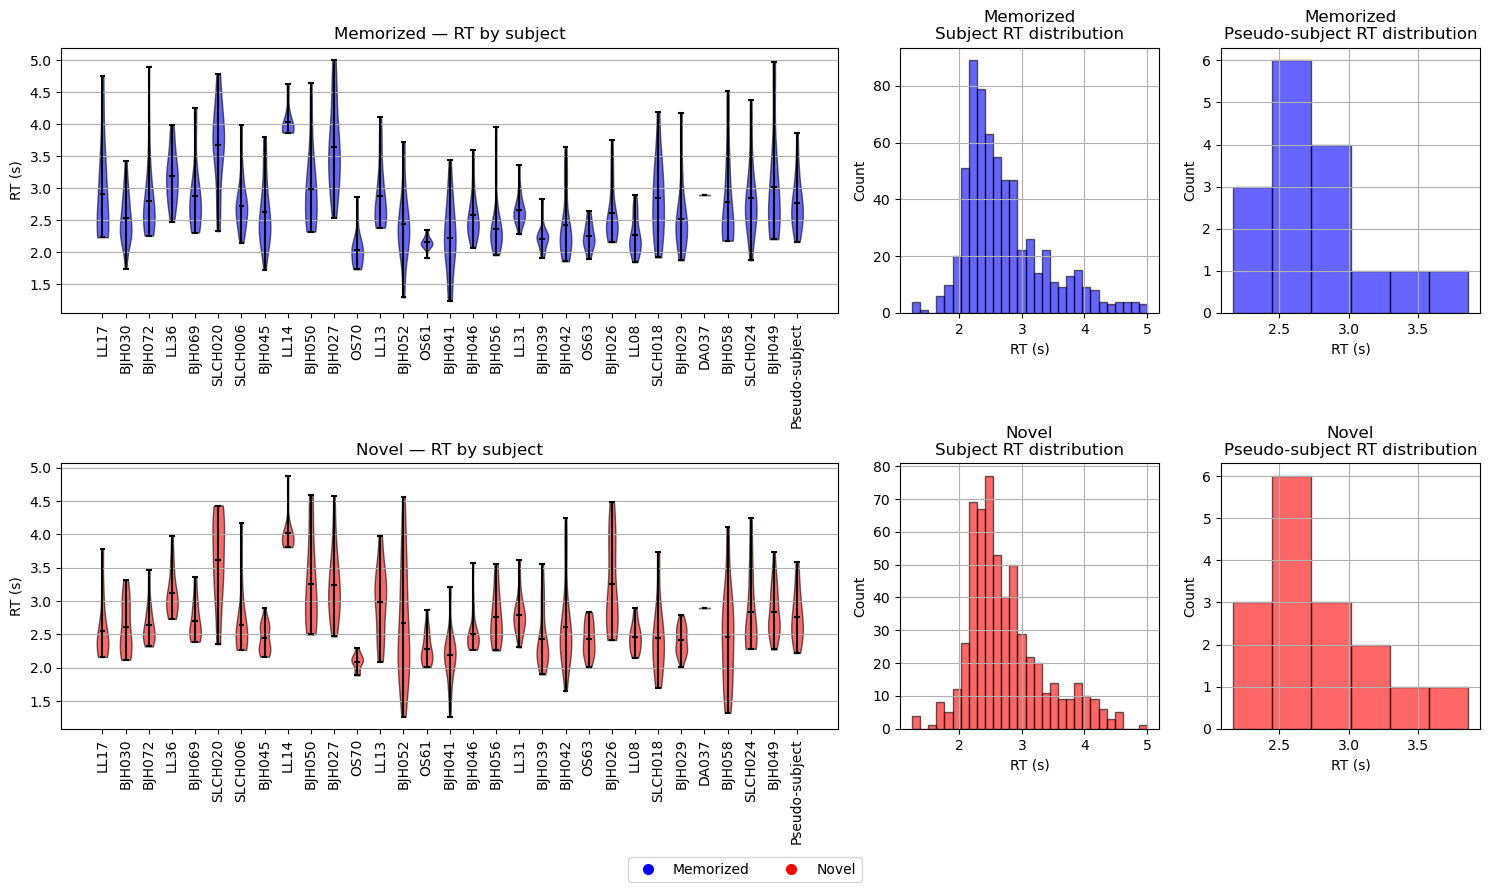

In [9]:
fig, axs = plt.subplots(2, 3,figsize=(15, 9),width_ratios=[6/10, 2/10, 2/10],sharey=False)
RT_type = 'RT'
conditions = [('1', 'Memorized'),('2', 'Novel')]

df_rt_all = pd.DataFrame(rt_mean_all.flatten(),columns=['RT'])
df_rt_all['Events'] = (['Memorized'] * nb_trials +['Novel'] * nb_trials)

bins_subject = np.histogram_bin_edges(df_RT.loc[df_RT['ev_id'].isin(['1', '2']), RT_type],bins='auto')
bins_super = np.histogram_bin_edges(df_rt_all['RT'],bins='auto')

for row, (ev, condition_name) in enumerate(conditions):

    color = color_event[row]
    ax = axs[row, 0]
    violin_data = []
    positions = []
    labels = []

    for i, subj in enumerate(subj_included):
        data = df_RT.loc[(df_RT['subject'] == subj) &(df_RT['ev_id'] == ev),RT_type].dropna().values
        if len(data) > 0:
            violin_data.append(data)
            positions.append(i)
            labels.append(subj)
    super_data = df_rt_all.loc[df_rt_all['Events'] == condition_name,'RT'].dropna().values
    if len(super_data) > 0:
        violin_data.append(super_data)
        positions.append(len(subj_included))
        labels.append('Pseudo-subject')
    parts = ax.violinplot(violin_data,positions=positions,showmeans=True,showmedians=False,showextrema=True)

    for body in parts['bodies']:
        body.set_facecolor(color)
        body.set_edgecolor('black')
        body.set_alpha(0.6)

    for key in ['cmeans', 'cmins', 'cmaxes', 'cbars']:
        if key in parts:
            parts[key].set_color('black')

    ax.set_xticks(positions)
    ax.set_xticklabels(labels, rotation=90)

    ax.set_ylabel('RT (s)')
    ax.set_title(f'{condition_name} — RT by subject')
    ax.grid(True, axis='y')

    ax = axs[row, 1]

    data = df_RT.loc[df_RT['ev_id'] == ev,RT_type].dropna()

    ax.hist(data,bins=bins_subject, alpha=0.6,color=color,edgecolor='black')
    ax.set_xlabel('RT (s)')
    ax.set_ylabel('Count')
    ax.set_title(f'{condition_name}\nSubject RT distribution')
    ax.grid(True)

    ax = axs[row, 2]
    data = df_rt_all.loc[df_rt_all['Events'] == condition_name,'RT'].dropna()
    ax.hist(data,bins=bins_super,alpha=0.6,color=color,edgecolor='black')
    ax.set_xlabel('RT (s)')
    ax.set_ylabel('Count')
    ax.set_title(f'{condition_name}\nPseudo-subject RT distribution')
    ax.grid(True)

handles = [Line2D([0], [0], marker='o',linestyle='',color=color_event[0],label='Memorized',markersize=7),
    Line2D([0], [0],marker='o',linestyle='',color=color_event[1],label='Novel',markersize=7)]

fig.legend(handles=handles,loc='upper center',ncol=2,frameon=True,bbox_to_anchor=(0.5, .01))
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [31]:

name_tp = {'0_pc1' : 'Crossing Net1', 
           '0_pc2' : 'Crossing Net2', 
           '0_pc3' : 'Crossing Net3', 
           'min_pc2' : 'Maxima Net2', 
           'bump_pc3' : 'Late Maxima Net3'}
name_measure = {'delay': 'Delay', 'ampl': 'Amplitude'}

find_tp = {'0_pc1': lambda x, tr : get_cross_point(tr, x, tstart=90, tend=150), 
           '0_pc2': lambda x, tr :  get_cross_point(tr, x, tstart=60, tend=150), 
           '0_pc3': lambda x, tr : get_cross_point(tr, x, tstart=120, tend=140), 
           'min_pc2': lambda x, tr : np.argmax(x[tr, 100:]) + 100, 
           'bump_pc3' : lambda x, tr : 115 + np.argmax(x[tr, 115:]),
           'desc_slop_pc2': lambda x, tr : get_slop_pc2(tr, x, time=time)[0] , 
           'asc_slop_pc2' : lambda x, tr : get_slop_pc2(tr, x, time=time)[1], 
           'slop_pc3': lambda x, tr : get_slop_pc3(tr, x, time=time),
           'area_under_pc2': lambda x, tr : area_pc2(tr, x)[0], 
           'area_above_pc2': lambda x, tr : area_pc2(tr, x)[1]}

# from cluster
r = 100
r_perm = 1000
path = OUT_PATH + f'/Behavior_{dataset_label}/'
pc_use = 0

with open(path+ f'tp_metr_{r}.pkl', 'rb') as file:
    metr = pickle.load(file)

with open(path+ f'tp_corr_{r}.pkl', 'rb') as file:
    corr = pickle.load(file)

with open(path+ f'tp_corr_{r}_perm.pkl', 'rb') as file:
    corr_perm = pickle.load(file)

with open(path+ f'tp_trans_500.pkl', 'rb') as file:
    trans = pickle.load(file)

file = OUT_PATH + f'/Behavior_{dataset_label}/tp_rt_{r}.pkl'
with open(file, "rb") as f:
    rt = pickle.load(f)
    
with open(path + f"results_median_{r}_{r_perm}.pkl", "rb") as f:
    results_median = pickle.load(f)

correlation = pd.DataFrame(corr, columns = ['corr', 'p', 'test', 'condi', 'type_m', 'iter'])
correlation_perm = pd.DataFrame(corr_perm, columns = ['corr', 'p', 'test', 'condi', 'type_m', 'iter_perm', 'iter'])
correlation['corr'] = pd.to_numeric(correlation['corr'])
correlation_perm['corr'] = pd.to_numeric(correlation_perm['corr'])
metrics_list = list(name_tp.keys())

In [11]:
results_median["p_adj"] = (results_median.groupby("condi")["p_median"].transform(adjust_pvalues))
results_median["sig_level"] = results_median["p_adj"].map(significance)

0_pc1 0 delay 0.6372277675160913
0_pc2 0 delay 0.3077456564930853
0_pc3 0 delay 0.24296304007536756
min_pc2 0 delay 0.38372231173890226
min_pc2 0 ampl -0.12247095414221285
bump_pc3 0 delay 0.6305221571420736
bump_pc3 0 ampl -0.0709436804495347
0_pc1 1 delay 0.6036892832672754
0_pc2 1 delay 0.591026307228331
0_pc3 1 delay 0.6510815599232341
min_pc2 1 delay 0.6614764196310559
min_pc2 1 ampl -0.2376197816970436
bump_pc3 1 delay 0.2698294906510788
bump_pc3 1 ampl -0.08268344109769055


KeyError: 'p_adj'

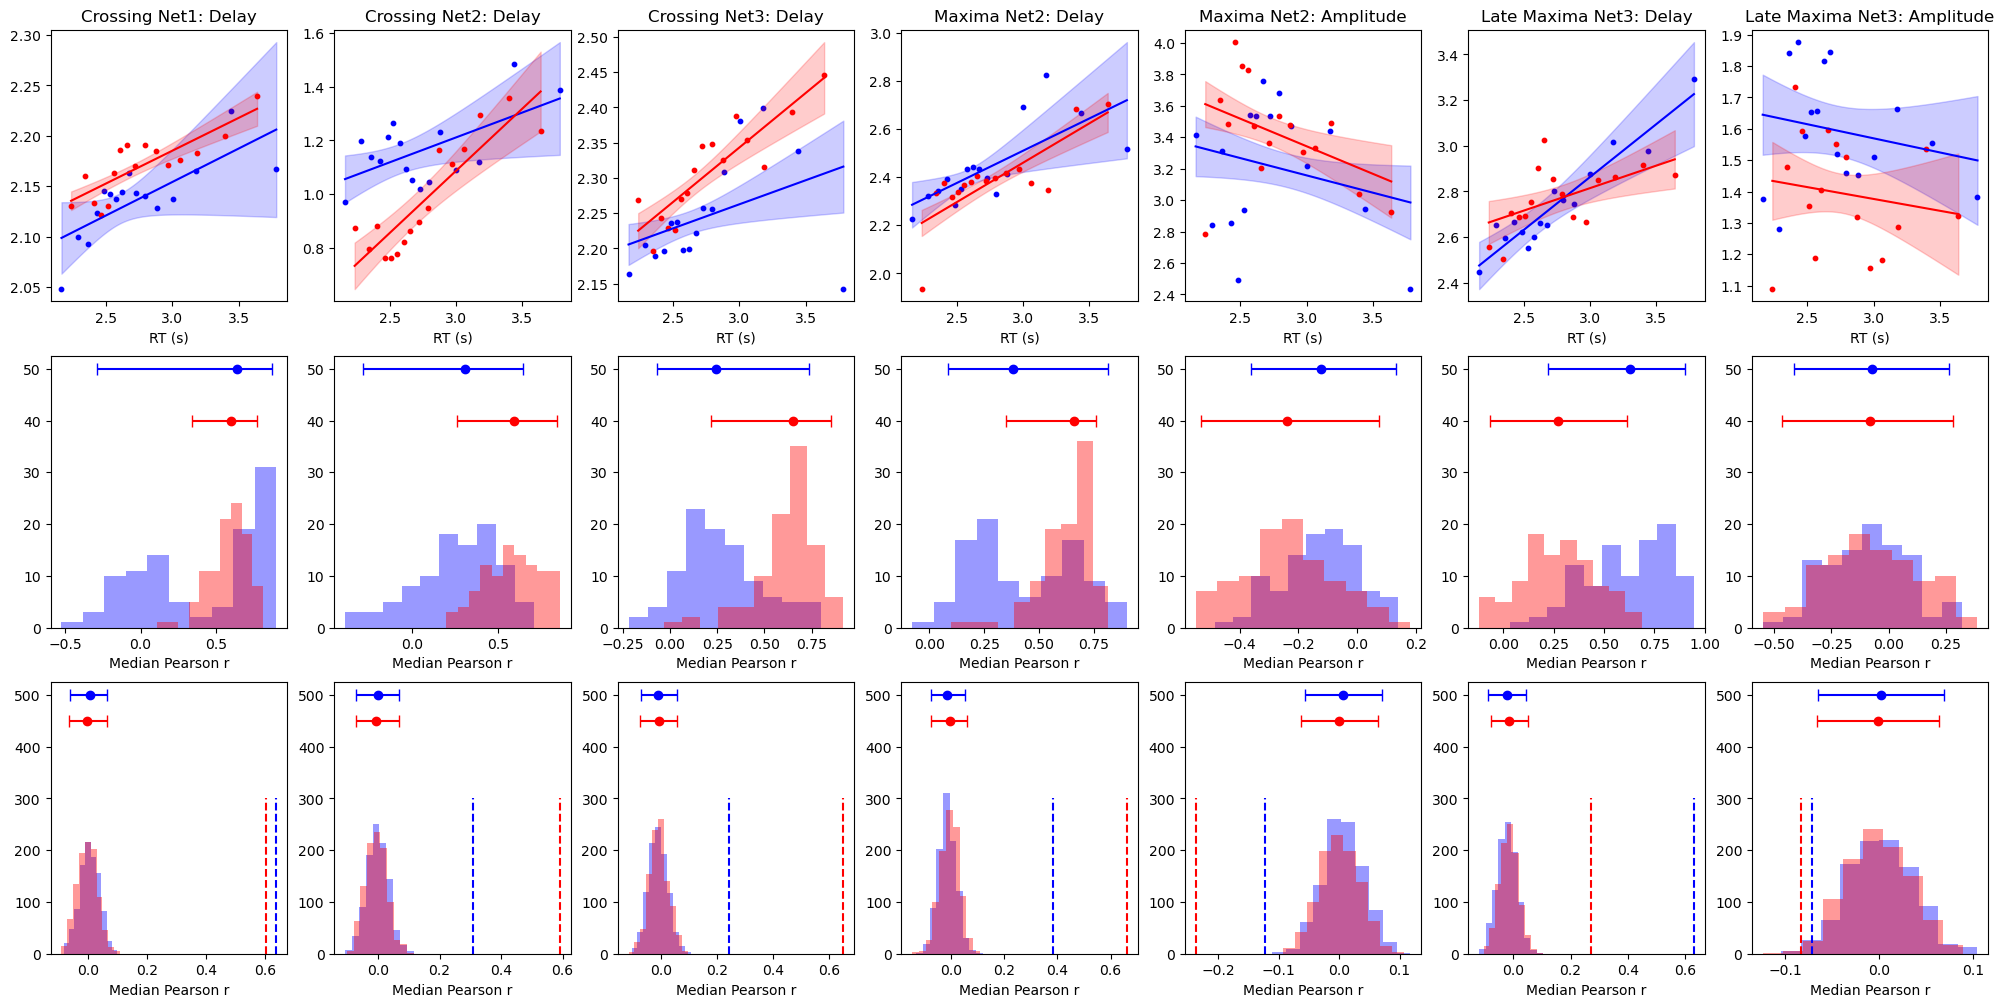

In [32]:
fig, ax=plt.subplots(3, 7, figsize=(25, 12))

for_leg1 = []
for_leg2=[]
sub_r_to_plot =100
markers = ['o', '^', 's', 'D', 'P']

for condi in ['0', '1'] :
    iaxs=0
    for it, t_try in  enumerate(metrics_list) :
        for im, mesure in enumerate( ['delay', 'ampl', 'slope', 'auc']): 
            m = correlation.query("test == @t_try and condi == @condi and type_m == @mesure")
            if m.shape[0] != 0 :
                ax[0][iaxs].set_title(name_tp[t_try] + ': ' + name_measure[mesure])
                # linear fit curve per run
                metrics= metr[m.index, :]
                rt_runs =rt[:, int(condi), :]
                xs = []
                ys=[]
                slopes=[]
                for run in range(sub_r_to_plot) :
                    is_na = np.where(np.isnan(metrics[run, :]))
                    if np.sum(is_na) == 0 :
                        fit = linregress(rt_runs[run, :], metrics[run,:])
                        x = np.linspace(rt_runs[run, :].min(), rt_runs[run, :].max(), 100)
                        y=fit.slope * x + fit.intercept
                        xs.append(x)
                        ys.append(y)

                #ax[0][iaxs].scatter(rt_runs[run], metrics[run], s=10, c=color_event[int(condi)],  alpha = 1, marker=markers[run]) #rt_runs[:sub_r_to_plot],cmap=cmap_condi[int(condi)], alpha = 1)
                ax[0][iaxs].scatter(rt_runs.mean(axis=0), metrics.mean(axis=0), s=10, c=color_event[int(condi)],  alpha = 1, marker=markers[0]) #rt_runs[:sub_r_to_plot],cmap=cmap_condi[int(condi)], alpha = 1)
                X_mean=np.stack(xs, axis=0).mean(0)
                Y_mean=np.stack(ys, axis=0).mean(0)
                Y_sd=np.stack(ys, axis=0).std(0)
                ax[0][iaxs].plot(X_mean, Y_mean, color=color_event[int(condi)], alpha = 1)
                ax[0][iaxs].fill_between(X_mean, Y_mean-Y_sd, Y_mean + Y_sd,  color=color_event[int(condi)],alpha = 0.2)
                ax[0][iaxs].set_xlabel('RT (s)')
                iaxs+=1

p_perm_list = []

for condi in ['0', '1'] :
    idx_ = 0
    for it, t_try in  enumerate(metrics_list) :
        for im, mesure in enumerate( ['delay', 'ampl', 'slope', 'auc']) :

            m = correlation.query("test == @t_try and condi == @condi and type_m == @mesure")
            m_perm = correlation_perm.query("test == @t_try and condi == @condi and type_m == @mesure")

            if m.shape[0] != 0 :
                r_real = np.asarray([float(q) for q in m['corr'].values])
                real_median = np.median(r_real)
                real_ci = np.percentile(r_real, [2.5, 97.5])
                print(t_try, condi, mesure, real_median)

                ax[1][idx_].hist(
                    r_real,
                    color=color_event[int(condi)],
                    alpha=0.4
                )

                ax[1][idx_].errorbar(
                    real_median,
                    50 - int(condi)*10,
                    xerr=[[real_median - real_ci[0]],
                          [real_ci[1] - real_median]],
                    fmt='o',
                    color=color_event[int(condi)],
                    capsize=4,
                    markersize=6
                )

                ax[1][idx_].set_xlabel('Median Pearson r')
                m_perm = m_perm.copy()
                m_perm['corr'] = m_perm['corr'].astype(float)
                m_perm['iter_perm'] = m_perm['iter_perm'].astype(int)
                m_perm['iter'] = m_perm['iter'].astype(int)

                r_perm =( m_perm.groupby('iter_perm')['corr'].median().values)
                perm_mean = np.mean(r_perm)
                perm_median = np.median(r_perm)
                perm_ci = np.percentile(r_perm, [2.5, 97.5])

                ax[2][idx_].hist(r_perm,color=color_event[int(condi)],alpha=0.4)
                ax[2][idx_].errorbar(perm_median,500 - int(condi)*50,
                                     xerr=[[perm_median - perm_ci[0]],[perm_ci[1] - perm_median]],
                                     fmt='o',color=color_event[int(condi)],capsize=4,markersize=6)
                ax[2][idx_].vlines(real_median, ymin=0, ymax=300, color=color_event[int(condi)], ls='--',)
                ax[2][idx_].set_xlabel('Median Pearson r')
            
                idx_+=1
                
for condi in [0, 1]:
    idx_ = 0

    for t_try in metrics_list:
        for mesure in ['delay', 'ampl', 'slope', 'auc']:
            row = results_median.query("condi == @condi and test == @t_try and type_m == @mesure")
            if row.shape[0] == 0:
                continue
            p_= row['p_adj'].iloc[0]
            sign =significance(p_)
            ax[1, idx_].text(0.5,0.9 - 0.05*int(condi),f'{sign}',transform=ax[1, idx_].transAxes,ha='right',va='top',fontsize=15,color=color_event[int(condi)])
            idx_ += 1

legend_elements = [Line2D([], [], color='k', lw=2),
                   Line2D([], [], color='black', marker='o',linestyle='None', markersize=3),
                   Line2D([], [], color=color_event[0], marker='s',linestyle='None', markersize=7),
                   Line2D([], [], color=color_event[1], marker='s',linestyle='None', markersize=7)]

ax[0][-1].legend(
    handles=legend_elements,
    labels=['Mean±SD Linear fit', 'Mean value over runs', 'Memorized', 'Novel'], 
    bbox_to_anchor = (2.2, 0)
)

legend_elements = [
    Line2D([0], [0], marker='o', color='k', linestyle='None',
           markersize=6, label='Median Pearson r'),

    Line2D([0], [0], marker='|', color='k', linestyle='-',
           markersize=8, lw=1.5, label='95% CI'), 
]

ax[1][-1].legend(handles=legend_elements, bbox_to_anchor = (2, 0))

legend_elements = [
    Line2D([0], [0], marker='o', color='k', linestyle='None',
           markersize=6, label='Median Pearson r permuted'),
    Line2D([0], [0], marker='|', color='k', linestyle='-',
           markersize=8, lw=1.5, label='95% CI permuted'),    
    Line2D([0], [0], marker=None, color='k', linestyle='--',
            lw=1.5, label='Median Person r'), ]

ax[2][-1].legend(handles=legend_elements,bbox_to_anchor = (2.2, 0))

for a in ax.flatten():
    a.grid()

/tmp/ipykernel_11121/2126241393.py:130: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


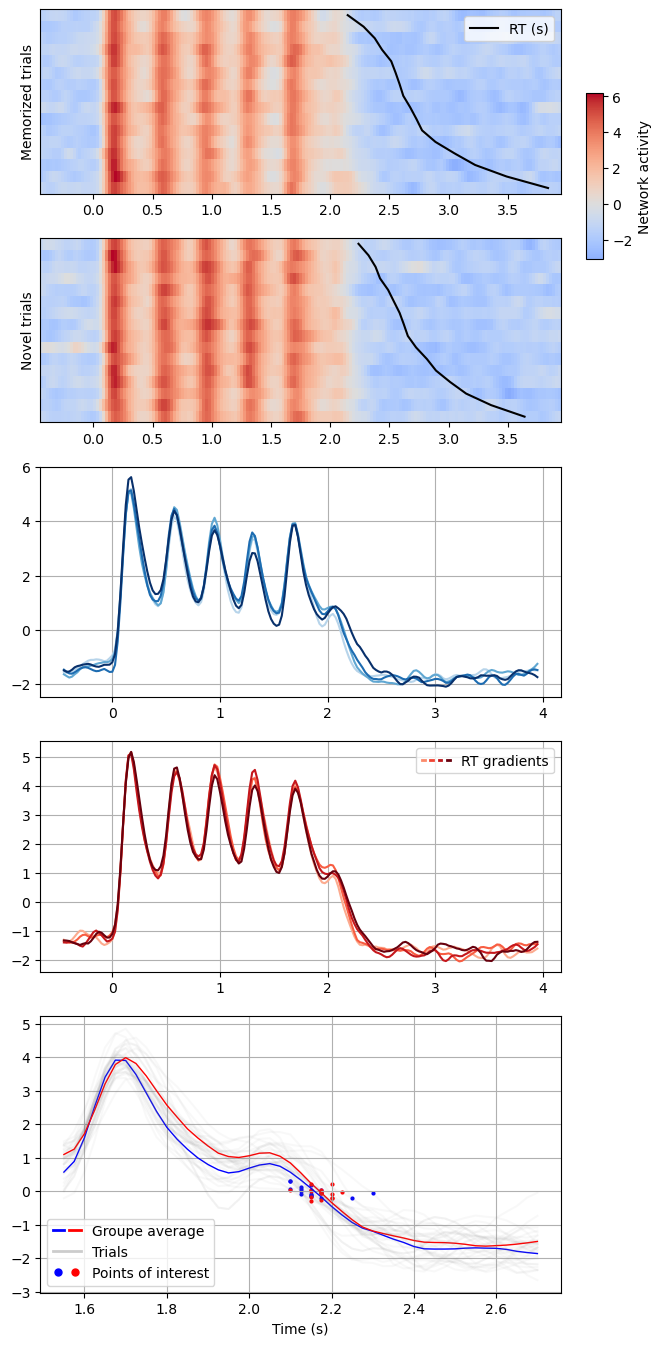

In [ ]:
fig, ax = plt.subplots(5, 1, figsize=(10/1.2, 20/1.2), sharex=False, gridspec_kw={'right': 0.75}, height_ratios=[8/60, 8/60, 10/60, 10/60, 12/60])
pc =0
titles = ["Memorized", "Novel"]

dataset_label = '_mf70-160'
pc_use= pc
r=500
n_cat = 4
colors1 = cm.Blues(np.linspace(0.3, 1, n_cat))  
colors2 = cm.Reds(np.linspace(0.3, 1, n_cat))  
col = [colors1, colors2]
file = OUT_PATH + f'/Behavior{dataset_label}/tp_rt_{r}.pkl'
with open(file, "rb") as f:
    rt = pickle.load(f)
file = OUT_PATH + f'/Behavior{dataset_label}/tp_trans_{r}.pkl'
with open(file, "rb") as f:
    trans = pickle.load(f)
# Heatmaps without individual colorbars
hm0 = sns.heatmap(trans[0, pc, 0, :, 20:],cmap='coolwarm',center=0,ax=ax[0],yticklabels=False,cbar=False)
hm1 = sns.heatmap(trans[0, pc, 1, :, 20:], cmap='coolwarm',center=0,ax=ax[1], yticklabels=False,cbar=False)
cax = fig.add_axes([0.78, 0.73, 0.02, 0.1])  # [left, bottom, width, height]
cbar = fig.colorbar(hm0.collections[0],cax=cax,orientation='vertical')
cbar.set_label('Network activity')

for i, (a, rt) in enumerate(zip(ax[:2], [rt[0, 0, :], rt[0, 1, :]])):

    # Hide heatmap x-axis
    a.set_xticks([])
    a.set_xticklabels([])

    ax_rt = a.twiny()
    ax_rt.xaxis.set_ticks_position('bottom')
    ax_rt.xaxis.set_label_position('bottom')
    ax_rt.spines['bottom'].set_position(('outward', 0))  

    y = np.arange(nb_trials) + 0.5
    ax_rt.plot(rt, y, color='k', lw=1.5, label ='RT (s)')
    ax_rt.set_xlim(time[20], time[-1])

    a.set_ylabel(f'{titles[i]} trials')
    if i == 0 : ax_rt.legend()

# grp
file = OUT_PATH + f'/Behavior{dataset_label}/tp_rt_{r}.pkl'
with open(file, "rb") as f:
    rt = pickle.load(f)

file = OUT_PATH + f'/Behavior{dataset_label}/tp_trans_{r}.pkl'
with open(file, "rb") as f:
    trans = pickle.load(f)

n_runs, n_cond, n_trials = rt.shape
_, n_pc, _, _, n_time = trans.shape

n_cat = 4
grp = int(nb_trials/n_cat)
mean_transform = np.zeros((n_pc, n_cond, n_cat, n_time))

for cond in range(n_cond):
    rt_ = rt[:, cond, :].reshape(-1)
    tr = trans[:, :, cond, :, :]
    tr = tr.transpose(0, 2, 1, 3).reshape(-1, n_pc, n_time)
    order = np.argsort(rt_)
    rt_sorted = rt_[order]
    tr_sorted = tr[order]
    bins = np.array_split(np.arange(len(rt_sorted)), n_cat)

    for cat, idx in enumerate(bins):
        mean_transform[:, cond, cat] = tr_sorted[idx].mean(axis=0)

for condi in range(2) :  
    for  cat in range(n_cat) :
        ax[2+condi].plot(time[20:], mean_transform[pc, condi, cat,20:], c=col[condi][cat])
        ax[2+condi].grid(True)


from matplotlib.legend_handler import HandlerTuple
blues = plt.cm.Blues([0.4, 0.6, 0.8, 1.0])
gradient_lines = tuple(Line2D([0], [0], color=c, lw=2) for c in blues)
ax[3].legend([gradient_lines],["RT gradients"],handler_map={tuple: HandlerTuple(ndivide=None)}, loc='upper right')

reds = plt.cm.Reds([0.4, 0.6, 0.8, 1.0])
gradient_lines = tuple(Line2D([0], [0], color=c, lw=2) for c in reds)
ax[3].legend([gradient_lines],["RT gradients"],handler_map={tuple: HandlerTuple(ndivide=None)}, loc='upper right')

# correlation over 500 runs
zoom_in_id = 100
zoom_in_id_end = -50

for i in range(2) :
    ax[4].plot(time[zoom_in_id:zoom_in_id_end], trans[0, pc, i, :, zoom_in_id:zoom_in_id_end].mean(0), c=color_event[i], linewidth= 1, label =titles[i])
    
    if pc == 2:
        list_tp = ['bump_pc3', '0_pc3'] 
    elif pc==1 : 
        list_tp = ['min_pc2', '0_pc2']
    elif pc==0 : 
        list_tp = ['0_pc1']

    for spe_tp in list_tp : 
        peaks = np.array([find_tp[spe_tp](trans[0, pc, i, :, :][:, :], tr) for tr in range(nb_trials)])

        for tr in range(nb_trials):
            ax[4].plot(time[zoom_in_id:zoom_in_id_end], trans[0, pc, i, tr, zoom_in_id:zoom_in_id_end],  color='grey', alpha = 0.05)
            ax[4].scatter(time[peaks[tr]], trans[0, pc, i, tr, peaks[tr]],s=4, color=color_event[i]) 

            if tr == 0 :
                ax[4].plot(time[zoom_in_id:zoom_in_id_end], trans[0, pc, i, tr, zoom_in_id:zoom_in_id_end],  color='grey', alpha = 0.05, label = 'Trials')
                ax[4].scatter(time[peaks[tr]], trans[0, pc, i, tr, peaks[tr]],s=4, color=color_event[i], label='points of interest') 

handles = (
    Line2D([0], [0], color=color_event[0], lw=2),
    Line2D([0], [0], color=color_event[1], lw=2),
)

trial_handle = Line2D([0], [0], color='grey', alpha=0.4, lw=2)
poi_handles = (
    Line2D([0], [0], marker='o', linestyle='', color=color_event[0], markersize=5),
    Line2D([0], [0], marker='o', linestyle='', color=color_event[1], markersize=5),
)

ax[4].legend(
    [handles, trial_handle, poi_handles],
    ['Groupe average', 'Trials', 'Points of interest'],
    handler_map={tuple: HandlerTuple(ndivide=None)}, 
    loc='lower left'
)
ax[4].set_xlabel('Time (s)')
ax[4].grid()
plt.tight_layout()

# Granger Causality

In [20]:
X_0,  X_0_old, X_0_new, y_0, true_trials = prep_data_trial(band, method_pca, None, subj_included_restricted[16], 0,tfr_path, nb_trials=nb_trials-1)
X_1,  X_1_old, X_1_new, y_1, true_trials = prep_data_trial(band, method_pca, None,  subj_included_restricted[16], 1,tfr_path, nb_trials=nb_trials-1)
X_2,  X_2_old, X_2_new, y_2, true_trials = prep_data_trial(band,method_pca, None, subj_included_restricted[16], 2,tfr_path, nb_trials=nb_trials-1)

X_=[X_0, X_1, X_2]
X_old=[X_0_old, X_1_old, X_2_old]
X_new=[X_0_new, X_1_new, X_2_new]

In [21]:
net_normal = {}
net_reverse = {}

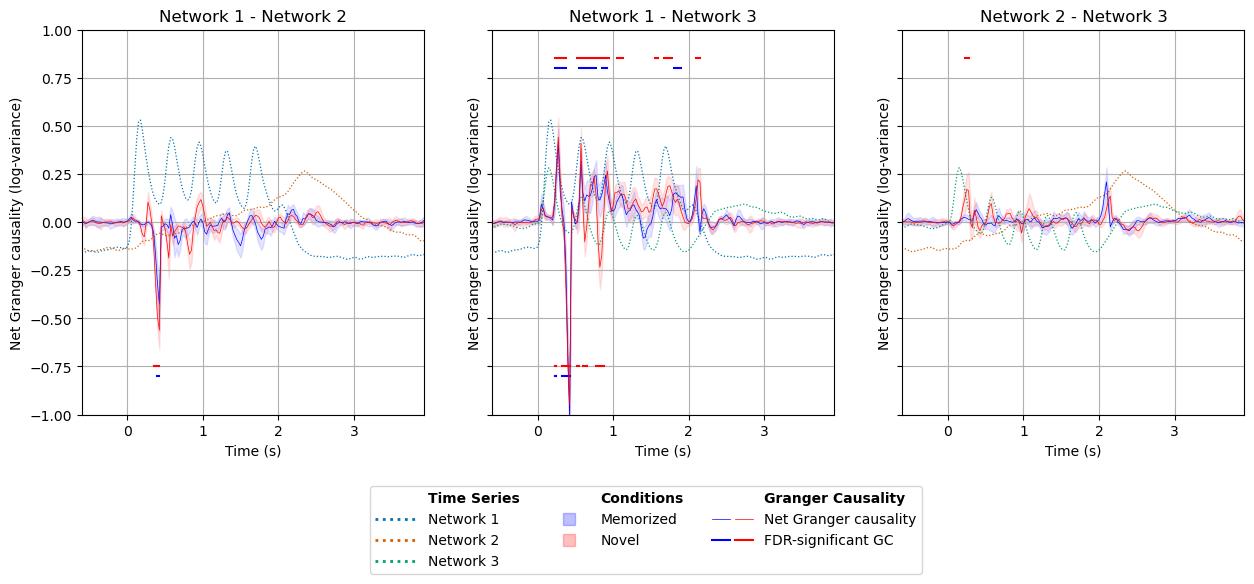

In [24]:
# NORMAL
nb_run = 20
n_perm = 100
surrogate_models = ['circular', 'shuffle', 'block']
fig, ax = plt.subplots(1, 3,sharey=True,figsize=(15, 5))

for i, (idx0, idx1) in enumerate([(0, 1),(0, 2),(1, 2)]):
    ax[i].plot(time,np.mean(X_[idx0], axis=0) * 0.1,color=col_pc[idx0],linewidth=0.9,ls=':',alpha=1)
    ax[i].plot(time,np.mean(X_[idx1], axis=0) * 0.1,color=col_pc[idx1],linewidth=0.9,ls=':',alpha=1)

    for j, condition in enumerate(['old', 'new']):
        GC = {}
        significant = {}
        for idx_label in [f'{idx0}to{idx1}',f'{idx1}to{idx0}']:
            GC_obs_runs = None
            significant_surrogate = {}
            for sur_model in surrogate_models:
                gc_obs_runs = []
                gc_null_runs = []
                for r in range(nb_run):
                    path = (OUT_PATH+ '/Granger_mf70-160/high_gamma/'+ f'{idx_label}_{condition}_{sur_model}{n_perm}_r{r}.npz')
                    d = np.load(path)
                    gc_obs_runs.append(d['gc_obs']) # (182,)
                    gc_null_runs.append(d['gc_null']) # (182, n_perm)
                    if r == 0: tend = d['tend']

                gc_obs_runs = np.stack(gc_obs_runs,axis=0) #(nb_run, 182)
                gc_null_runs = np.stack(gc_null_runs,axis=0) # (nb_run, 182, n_perm)
                if GC_obs_runs is None:
                    GC_obs_runs = gc_obs_runs

                # Statistic 
                Tobs = np.mean(gc_obs_runs,axis=0) #(182,)
                Tnull = np.mean(gc_null_runs,axis=0) # (182, n_perm)
                p_emp = (1+ np.sum(Tnull >= Tobs[:, None],axis=1)) / (n_perm + 1)    # (182,)
                
                reject, p_fdr, _, _ = multipletests(p_emp,alpha=0.05,method='fdr_bh')
                significant_surrogate[sur_model] = reject

            significant[idx_label] = (significant_surrogate['circular']& significant_surrogate['shuffle'] & significant_surrogate['block'])
            GC[idx_label] = GC_obs_runs

        gc_net_runs = (GC[f'{idx0}to{idx1}']- GC[f'{idx1}to{idx0}'])
        net_normal[(idx0, idx1, condition)] = gc_net_runs

        gc_net_mean = np.mean(gc_net_runs,axis=0)
        gc_net_std = np.std(gc_net_runs,axis=0)

        # Plot
        ax[i].plot(tend,gc_net_mean,color=color_event[j],linewidth=0.5)
        ax[i].fill_between(tend,gc_net_mean - gc_net_std,gc_net_mean + gc_net_std,alpha=0.1,color=color_event[j])

        pval1 = np.where(((np.mean(GC[f'{idx0}to{idx1}'],axis=0) > 0.2) & significant[f'{idx0}to{idx1}']),0.8 + j * 0.05,np.nan)
        ax[i].plot(tend,pval1,color=color_event[j])
        
        pval2 = np.where(((np.mean(GC[f'{idx1}to{idx0}'],axis=0) > 0.2) & significant[f'{idx1}to{idx0}']),-0.8 + j * 0.05,np.nan)
        ax[i].plot(tend,pval2,color=color_event[j])

    ax[i].set_ylim(-1, 1)
    ax[i].set_ylabel('Net Granger causality (log-variance)')
    ax[i].set_title(f'Network {idx0 + 1} - Network {idx1 + 1}')
    ax[i].grid()
    ax[i].set_xlim(np.min(tend),np.max(tend))
    ax[i].set_xlabel('Time (s)')

# Legend
leg_el = []
leg_label = []
for pc in [0, 1, 2]:
    line = Line2D([], [],color=col_pc[pc],lw=2,ls=':')
    leg_el.append(line)
    leg_label.append( f'Network {pc + 1}')

lines_condi = [Line2D([], [],marker='s',color=color_event[0],alpha=0.25,linestyle='None',markersize=8),
                Line2D([], [],marker='s',color=color_event[1],alpha=0.25,linestyle='None',markersize=8)]
label_condi=['Memorized', 'Novel']

# Significant GC
lines_pval = [(Line2D([], [],alpha=1,linewidth=1.5,color=color_event[0]),
            Line2D([], [],alpha=1,linewidth=1.5,color=color_event[1]))]
label_pval = ['FDR-significant GC']

# Net GC
lines_gc = [(Line2D([], [],alpha=1,color=color_event[0],linewidth=0.5),
            Line2D([], [],alpha=1,color=color_event[1],linewidth=0.5))]
label_gc = ['Net Granger causality']

lines_tot = ([Line2D([], [], linestyle='None')]+ leg_el + [Line2D([], [], linestyle='None')]+ lines_condi+ [Line2D([], [], linestyle='None')]+ lines_gc+ lines_pval)
label_tot = ( ['Time Series'] + leg_label + ['Conditions'] + label_condi + ['Granger Causality'] + label_gc + label_pval)
leg = ax[-1].legend(lines_tot,label_tot,handler_map={    tuple: HandlerTuple(ndivide=None)},handlelength=3,bbox_to_anchor=(-0.75, -0.3),ncol=3,loc='center')

for h, txt in zip(leg.legend_handles,leg.get_texts()):
    if txt.get_text() not in (label_gc+ label_condi+ leg_label+ label_pval):
        h.set_visible(False)
        txt.set_weight('bold')


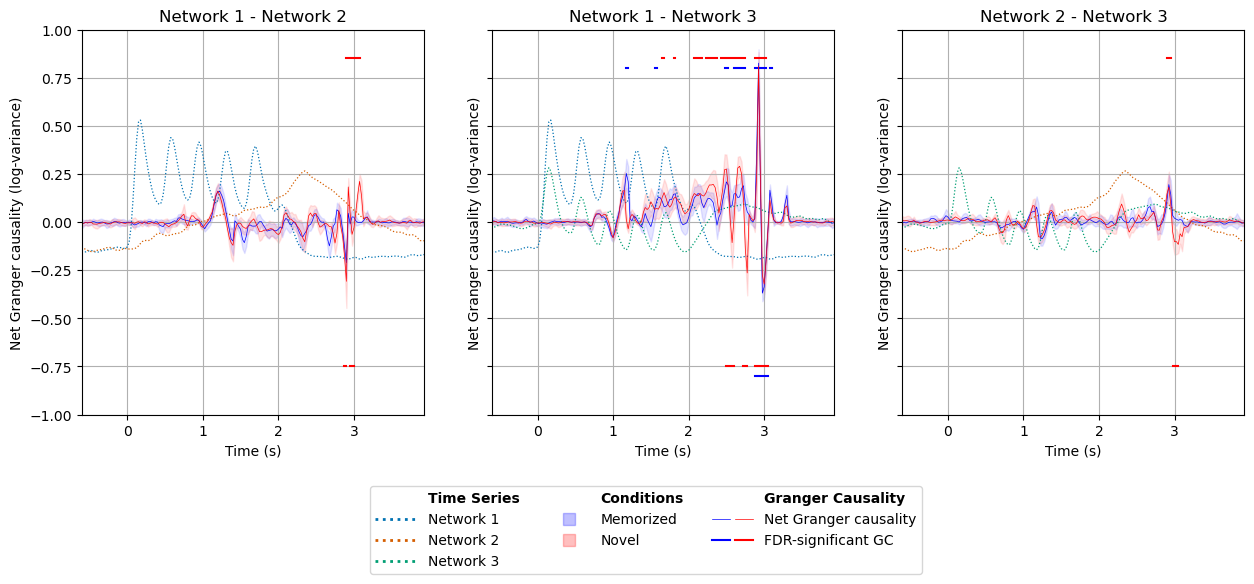

In [25]:
# REVERSED
nb_run = 20
n_perm = 100
surrogate_models = ['circular', 'shuffle', 'block']
fig, ax = plt.subplots(1, 3,sharey=True,figsize=(15, 5))

for i, (idx0, idx1) in enumerate([(0, 1),(0, 2),(1, 2)]):
    ax[i].plot(time,np.mean(X_[idx0], axis=0) * 0.1,color=col_pc[idx0],linewidth=0.9,ls=':',alpha=1)
    ax[i].plot(time,np.mean(X_[idx1], axis=0) * 0.1,color=col_pc[idx1],linewidth=0.9,ls=':',alpha=1)

    for j, condition in enumerate(['old', 'new']):
        GC = {}
        significant = {}
        for idx_label in [f'{idx0}to{idx1}',f'{idx1}to{idx0}']:
            GC_obs_runs = None
            significant_surrogate = {}
            for sur_model in surrogate_models:
                gc_obs_runs = []
                gc_null_runs = []
                for r in range(nb_run):
                    path = (OUT_PATH+ '/Granger_mf70-160/high_gamma/'+ f'{idx_label}_{condition}_{sur_model}{n_perm}_r{r}_reversed.npz')
                    d = np.load(path)
                    gc_obs_runs.append(d['gc_obs']) # (182,)
                    gc_null_runs.append(d['gc_null']) # (182, n_perm)
                    if r == 0: tend = d['tend']

                gc_obs_runs = np.stack(gc_obs_runs,axis=0) #(nb_run, 182)
                gc_null_runs = np.stack(gc_null_runs,axis=0) # (nb_run, 182, n_perm)
                if GC_obs_runs is None:
                    GC_obs_runs = gc_obs_runs

                # Statistic 
                Tobs = np.mean(gc_obs_runs,axis=0) #(182,)
                Tnull = np.mean(gc_null_runs,axis=0) # (182, n_perm)
                p_emp = (1+ np.sum(Tnull >= Tobs[:, None],axis=1)) / (n_perm + 1)    # (182,)
                
                reject, p_fdr, _, _ = multipletests(p_emp,alpha=0.05,method='fdr_bh')
                significant_surrogate[sur_model] = reject

            significant[idx_label] = (significant_surrogate['circular']& significant_surrogate['shuffle'] & significant_surrogate['block'])
            GC[idx_label] = GC_obs_runs

        gc_net_runs = (GC[f'{idx0}to{idx1}']- GC[f'{idx1}to{idx0}'])
        net_reverse[(idx0, idx1, condition)] = gc_net_runs

        gc_net_mean = np.mean(gc_net_runs,axis=0)
        gc_net_std = np.std(gc_net_runs,axis=0)

        # Plot
        ax[i].plot(tend,gc_net_mean,color=color_event[j],linewidth=0.5)
        ax[i].fill_between(tend,gc_net_mean - gc_net_std,gc_net_mean + gc_net_std,alpha=0.1,color=color_event[j])

        pval1 = np.where(((np.mean(GC[f'{idx0}to{idx1}'],axis=0) > 0.2) & significant[f'{idx0}to{idx1}']),0.8 + j * 0.05,np.nan)
        ax[i].plot(tend,pval1,color=color_event[j])
        
        pval2 = np.where(((np.mean(GC[f'{idx1}to{idx0}'],axis=0) > 0.2) & significant[f'{idx1}to{idx0}']),-0.8 + j * 0.05,np.nan)
        ax[i].plot(tend,pval2,color=color_event[j])

    ax[i].set_ylim(-1, 1)
    ax[i].set_ylabel('Net Granger causality (log-variance)')
    ax[i].set_title(f'Network {idx0 + 1} - Network {idx1 + 1}')
    ax[i].grid()
    ax[i].set_xlim(np.min(tend),np.max(tend))
    ax[i].set_xlabel('Time (s)')

# Legend
leg_el = []
leg_label = []
for pc in [0, 1, 2]:
    line = Line2D([], [],color=col_pc[pc],lw=2,ls=':')
    leg_el.append(line)
    leg_label.append( f'Network {pc + 1}')

lines_condi = [Line2D([], [],marker='s',color=color_event[0],alpha=0.25,linestyle='None',markersize=8),
                Line2D([], [],marker='s',color=color_event[1],alpha=0.25,linestyle='None',markersize=8)]
label_condi=['Memorized', 'Novel']

# Significant GC
lines_pval = [(Line2D([], [],alpha=1,linewidth=1.5,color=color_event[0]),
            Line2D([], [],alpha=1,linewidth=1.5,color=color_event[1]))]
label_pval = ['FDR-significant GC']

# Net GC
lines_gc = [(Line2D([], [],alpha=1,color=color_event[0],linewidth=0.5),
            Line2D([], [],alpha=1,color=color_event[1],linewidth=0.5))]
label_gc = ['Net Granger causality']

lines_tot = ([Line2D([], [], linestyle='None')]+ leg_el + [Line2D([], [], linestyle='None')]+ lines_condi+ [Line2D([], [], linestyle='None')]+ lines_gc+ lines_pval)
label_tot = ( ['Time Series'] + leg_label + ['Conditions'] + label_condi + ['Granger Causality'] + label_gc + label_pval)
leg = ax[-1].legend(lines_tot,label_tot,handler_map={    tuple: HandlerTuple(ndivide=None)},handlelength=3,bbox_to_anchor=(-0.75, -0.3),ncol=3,loc='center')

for h, txt in zip(leg.legend_handles,leg.get_texts()):
    if txt.get_text() not in (label_gc+ label_condi+ leg_label+ label_pval):
        h.set_visible(False)
        txt.set_weight('bold')
